In [1]:
import jax
import os

In [2]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

In [66]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
pico_a = {k: v for k, v in enumerate(ps.from_csv(fname))}
pico_a[len(pico_a)] = np.ones(pico_a[0].shape)

names_1qb = ["X1", "X2", "SX1", "SX2", "I1", "I2"]
angles_1qb = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi, 1.0, 0.0]

In [67]:
cal_1qb_gates = ps.calibrate_gateset(
    pico_a,
    angles_1qb,
    duration_1qb,
    dt,
    samples=32,
    names=names_1qb
)

Storing symbolic pulses...
Adjusting X1 by amplitude 1.00 for angle 1.50π
Adjusting X2 by amplitude 1.00 for angle 0.50π
Adjusting SX1 by amplitude 1.00 for angle 1.25π
Adjusting SX2 by amplitude 1.00 for angle 0.25π
Zero area signal. Adjusting I1 by amplitude 1.00 using angle.
Adjusting I2 by amplitude 0.00 for angle 0.00π


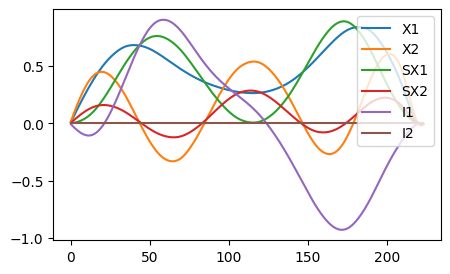

In [73]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
for i, (k, v) in enumerate(cal_1qb_gates.items()):
    ax.plot(ps.get_samples(v).real, label=names_1qb[i])
ax.legend(loc="upper right")

In [80]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"

base_2qb = {k: ps.from_csv(fname(k))[0] for k in ["default", "robust"]}
robust_2qb = {0: base_2qb["robust"], 1: base_2qb["robust"]}
default_2qb = {0: base_2qb["default"], 1: base_2qb["default"]}
names_2qb = ["+", "-"]

In [81]:
cal_2qb_robust = ps.calibrate_gateset(
    robust_2qb,
    [0.125 * np.pi, -0.125 * np.pi],
    duration_2qb,
    dt,
    samples=32,
    names=names_2qb
)

Storing symbolic pulses...
Adjusting + by amplitude 1.00 for angle 0.12π
Adjusting - by amplitude 1.00 for angle-0.12π


In [82]:
cal_2qb_default = ps.calibrate_gateset(
    default_2qb,
    [0.125 * np.pi, -0.125 * np.pi],
    duration_2qb,
    dt,
    samples=32,
    names=names_2qb
)

Storing symbolic pulses...
Adjusting + by amplitude 1.00 for angle 0.12π
Adjusting - by amplitude 1.00 for angle-0.12π


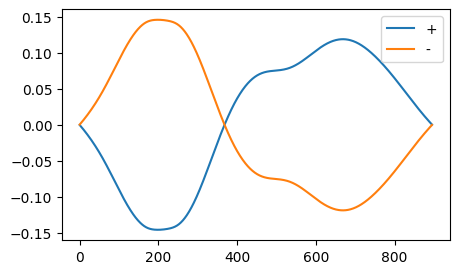

In [83]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
for i, (k, v) in enumerate(cal_2qb_robust.items()):
    ax.plot(ps.get_samples(v).real, label=names_2qb[i])
ax.legend(loc="upper right")